# Goal geometry and task metrics

Research scratchpad 1/2. Can a better-looking latent metric select a better physical action? These are lightweight reanalyses of existing PushT evidence, not new experiments. The original team's proposal supplies the rank-32 contrastive adapter; this consolidation does not claim that idea.

Run all cells with Python 3.10, NumPy, pandas and Matplotlib. Keep evidence.zip and provenance.json beside this notebook. No checkpoint, simulator, local project imports, network calls or output-file writes are needed. Gains below mean baseline minus alternative physical regret, in pixel-equivalent units. Each study keeps its own cohort; differing absolute errors are not a leaderboard.

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib, json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works from this folder or the repository root. Nothing is extracted or written.
HERE = (
    Path.cwd()
    if (Path.cwd() / "evidence.zip").is_file()
    else Path.cwd() / "auto_research"
)
provenance = json.loads((HERE / "provenance.json").read_text())
assert (
    hashlib.sha256((HERE / "evidence.zip").read_bytes()).hexdigest()
    == provenance["archive_sha256"]
)
archive = zipfile.ZipFile(HERE / "evidence.zip")
for item in provenance["files"]:
    assert (
        hashlib.sha256(archive.read(item["archive_path"])).hexdigest() == item["sha256"]
    )


def read_json(path):
    return json.loads(archive.read("docs/" + path))


def read_csv(path):
    return pd.read_csv(BytesIO(archive.read("docs/" + path)))


def read_arrays(path):
    # Materialize only this small archive; reject pickle-backed object arrays.
    with np.load(BytesIO(archive.read("docs/" + path)), allow_pickle=False) as saved:
        return {name: saved[name] for name in saved.files}


def paired_interval(matrix, seed):
    # Each row is a bank, each column a task. Repeated heads are averaged FIRST.
    matrix = np.asarray(matrix, float)
    assert matrix.ndim == 2 and min(matrix.shape) >= 2 and np.isfinite(matrix).all()
    banks, tasks = matrix.shape
    rng = np.random.default_rng(seed)
    chosen = rng.integers(banks, size=(10000, banks, 1))
    within = rng.integers(tasks, size=(10000, banks, tasks))
    draws = matrix[chosen, within].mean(axis=(1, 2))
    return np.array([matrix.mean(), *np.quantile(draws, [0.025, 0.975])])


def physical_error(poses, goal):
    position = np.linalg.norm(poses[..., :2] - goal[..., :2], axis=-1)
    angle = (poses[..., 2] - goal[..., 2] + np.pi) % (2 * np.pi) - np.pi
    return np.sqrt(position**2 + (50 * angle) ** 2)


plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)
print("Verified byte-identical evidence files:", len(provenance["files"]))
print("Source base:", provenance["base_revision"])


Verified byte-identical evidence files: 236
Source base: d07cd7878cb40ecbd9e1004ef7db6794eb08d1df


## 1. Averaging is not nuisance removal

Averaging squared distances to photos equals squared distance to their mean plus a candidate-independent constant. It still penalizes a candidate's nuisance coordinate. A quotient removes the span fitted to equivalent photos. The toy below is an algebra illustration only; lower latent cost is not evidence of better control. Equivalent-goal grouping is structured supervision.

In [2]:
goals = np.array([[0.0, -2.0], [0.0, -1.0], [0.0, 1.0], [0.0, 2.0]])
candidates = np.array([[0.0, 3.0], [1.0, 0.0]])
center = goals.mean(axis=0)
_, singular, vt = np.linalg.svd(goals - center, full_matrices=False)
basis = vt[singular > 1e-12].T
residual = candidates - center
prototype = np.square(residual).sum(axis=1)
quotient = prototype - np.square(residual @ basis).sum(axis=1)
assert prototype.argmin() == 1 and quotient.argmin() == 0
print(
    pd.DataFrame(
        {"task_error": [0.0, 1.0], "prototype": prototype, "quotient": quotient}
    )
)


   task_error  prototype      quotient
0         0.0        9.0  5.329071e-15
1         1.0        1.0  1.000000e+00


## 2. Goal quotient: unsupported primary, positive photo control

The fixed primary compares full global quotient with the same eight-photo prototype on 100 tasks in five banks. The patch variant was development-motivated and changes removable rank as well as locality. We retain its secondary negative/inconclusive result. Full protocol and reports are preserved in evidence.zip under docs/goal_quotient*.

In [3]:
tasks = read_csv("goal_quotient_results/task_rows.csv")
patch = read_csv("goal_quotient_results/patch_task_rows.csv")
primary_rows = tasks.query(
    "source == 'action_predicted' and goals == 8 and budget == 64"
)
wide = primary_rows.pivot(index=["seed", "task"], columns="method", values="regret")
assert wide.shape[0] == 100 and wide.index.get_level_values("seed").nunique() == 5
outcomes = []
for method in ["quotient_half", "quotient_full"]:
    delta = (wide.prototype - wide[method]).unstack("task")
    outcomes.append(
        [method, *paired_interval(delta, 491), int((delta.mean(axis=1) > 0).sum())]
    )
p = patch.query("source == 'action_predicted' and goals == 8 and budget == 64")
p = p.pivot(index=["seed", "task"], columns="method", values="regret")
delta = (p.prototype - p.patch_quotient).unstack("task")
outcomes.append(
    [
        "patch_quotient (secondary)",
        *paired_interval(delta, 491),
        int((delta.mean(axis=1) > 0).sum()),
    ]
)
photos = tasks.query(
    "source == 'action_predicted' and method == 'prototype' and budget == 64 and goals in [1,8]"
)
photos = photos.pivot(index=["seed", "task"], columns="goals", values="regret")
delta = (photos[1] - photos[8]).unstack("task")
outcomes.append(
    [
        "8 vs 1 photos (control)",
        *paired_interval(delta, 491),
        int((delta.mean(axis=1) > 0).sum()),
    ]
)
quotient_results = pd.DataFrame(
    outcomes, columns=["comparison", "gain", "lower95", "upper95", "positive_banks"]
)
print(quotient_results.round(4).to_string(index=False))
assert np.isclose(quotient_results.iloc[1].gain, -0.626, atol=0.001)
# Independently check selected physical labels against every saved state bank.
decisions = read_csv("goal_quotient_results/full_bank_decisions.csv")
for seed, group in decisions.groupby("seed"):
    saved = read_arrays(f"goal_quotient_results/state_banks/seed_{seed}.npz")
    poses = saved["candidate_states"][:, 2:5].reshape(-1, 64, 3)
    errors = physical_error(poses, saved["goal_poses"][:, None, :])
    for row in group.itertuples():
        actual = errors[row.task, row.selected_index]
        np.testing.assert_allclose(
            [row.selected_error, row.regret],
            [actual, actual - errors[row.task].min()],
            atol=1e-05,
            rtol=1e-06,
        )
print("Independent selected-error/regret checks:", len(decisions))


                comparison    gain  lower95  upper95  positive_banks
             quotient_half  0.0029  -0.3425   0.3787               2
             quotient_full -0.6262  -1.5515   0.0344               1
patch_quotient (secondary) -0.1506  -1.3205   0.7497               2
   8 vs 1 photos (control)  2.5487   1.5728   3.6466               5
Independent selected-error/regret checks: 1000


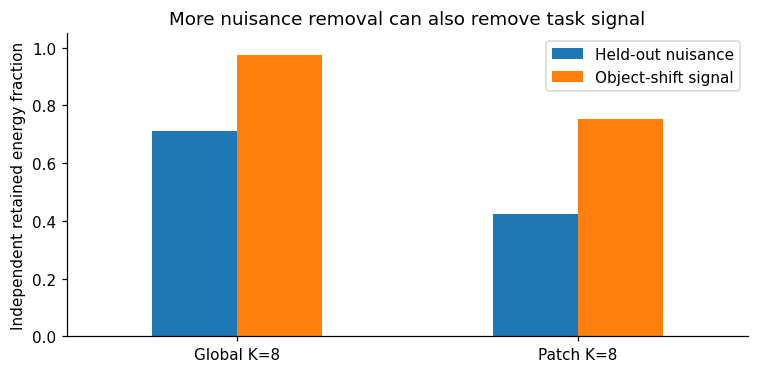

In [4]:
geometry = read_csv("goal_quotient_results/geometry.csv")
patch_geometry = read_csv("goal_quotient_results/patch_geometry.csv")
columns = ["heldout_nuisance_retained", "object_shift_signal_retained"]
comparison = pd.DataFrame(
    {
        "Global K=8": geometry.query("goals == 8")[columns].mean(),
        "Patch K=8": patch_geometry[columns].mean(),
    }
).T
comparison.rename(
    columns={
        "heldout_nuisance_retained": "Held-out nuisance",
        "object_shift_signal_retained": "Object-shift signal",
    }
).plot.bar(figsize=(7, 3.5), ylim=(0, 1.05), rot=0)
plt.ylabel("Independent retained energy fraction")
plt.title("More nuisance removal can also remove task signal")
plt.tight_layout()
plt.show()


The global primary gain is −0.626 [−1.551, +0.034]; unsupported, not proven equivalence or a definitive loss. Eight versus one photo gains +2.549 [1.573, 3.647]. The original prototype remains a strong control. The object-signal check is one x-shift, not all possible task changes.

In [ ]:
archive.close()